In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!unzip -q "/content/drive/MyDrive/SDNET2018.zip" -d /content/data

In [3]:
!unzip -q "/content/data/DATA_Maguire_20180517_ALL/SDNET2018.zip" -d /content/data/sdnet

In [4]:
import os
for root, dirs, files in os.walk("/content/data/sdnet"):
    if files:
        print(root, len(files))

/content/data/sdnet/D/CD 2025
/content/data/sdnet/D/UD 11595
/content/data/sdnet/P/CP 2608
/content/data/sdnet/P/UP 21726
/content/data/sdnet/W/CW 3851
/content/data/sdnet/W/UW 14287


In [5]:
import os
for root, dirs, files in os.walk("/content/data"):
    if files:
        print(root, len(files))

/content/data/DATA_Maguire_20180517_ALL 2
/content/data/sdnet/D/CD 2025
/content/data/sdnet/D/UD 11595
/content/data/sdnet/P/CP 2608
/content/data/sdnet/P/UP 21726
/content/data/sdnet/W/CW 3851
/content/data/sdnet/W/UW 14287


In [6]:
import os
import pandas as pd

base = "/content/data/sdnet"
folder_info = {
    "CD": ("deck", 1), "UD": ("deck", 0),
    "CP": ("pavement", 1), "UP": ("pavement", 0),
    "CW": ("wall", 1), "UW": ("wall", 0),
}

rows = []
for folder, (surface, label) in folder_info.items():
    path = os.path.join(base, folder[1], folder)
    for f in os.listdir(path):
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            rows.append({"path": os.path.join(path, f), "filename": f,
                         "surface": surface, "label": label})

df = pd.DataFrame(rows)
print(df.shape)
print(df["label"].value_counts())
print(df.groupby(["surface", "label"]).size())
print(df["filename"].head(10).tolist())

(56092, 4)
label
0    47608
1     8484
Name: count, dtype: int64
surface   label
deck      0        11595
          1         2025
pavement  0        21726
          1         2608
wall      0        14287
          1         3851
dtype: int64
['7021-133.jpg', '7004-21.jpg', '7048-182.jpg', '7019-38.jpg', '7046-177.jpg', '7008-40.jpg', '7048-141.jpg', '7045-84.jpg', '7045-161.jpg', '7035-96.jpg']


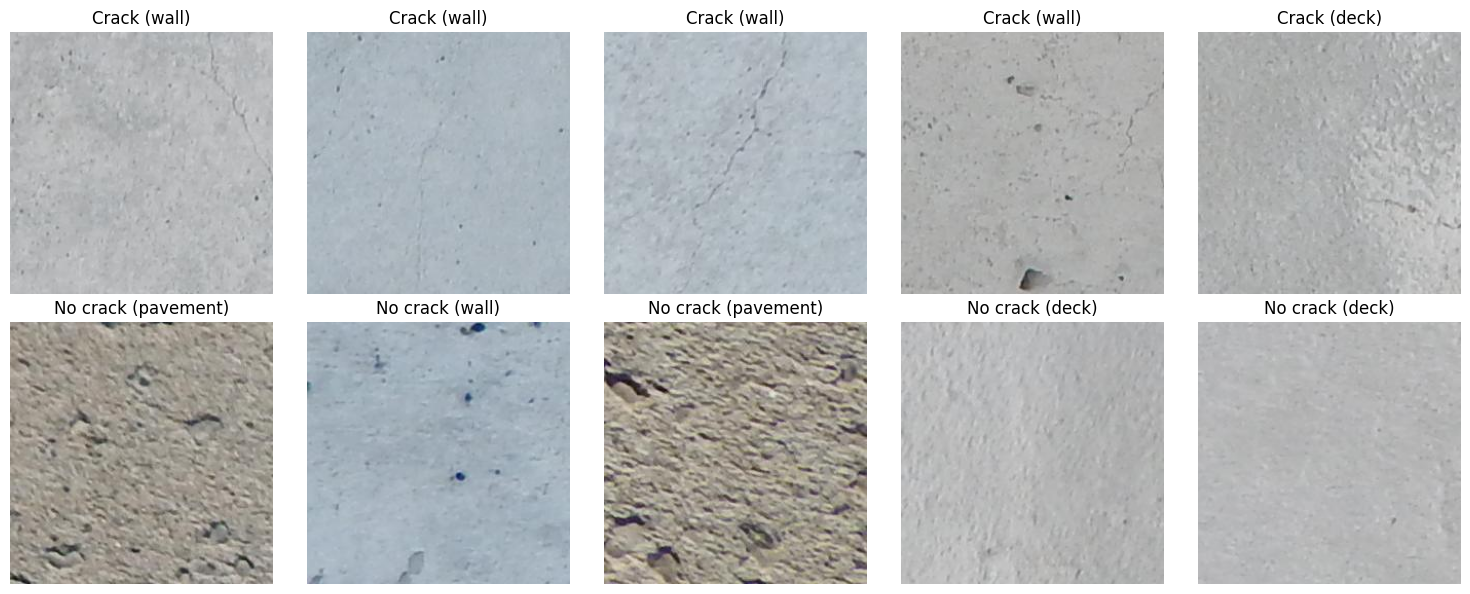

In [7]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, (label, name) in enumerate([(1, "Crack"), (0, "No crack")]):
    sample = df[df.label == label].sample(5, random_state=1)
    for j, (_, r) in enumerate(sample.iterrows()):
        axes[i, j].imshow(Image.open(r.path))
        axes[i, j].set_title(f"{name} ({r.surface})")
        axes[i, j].axis("off")
plt.tight_layout()
plt.show()

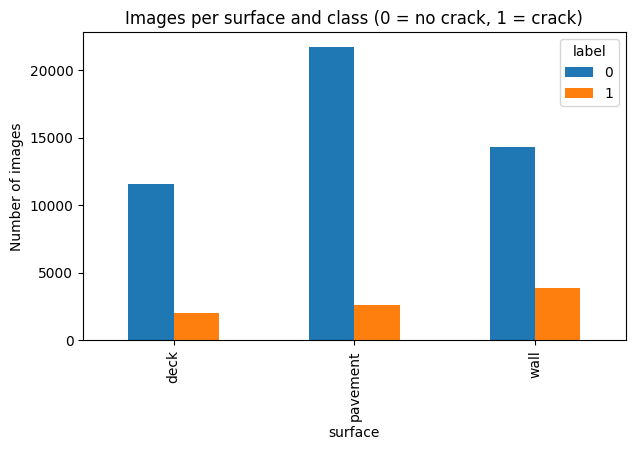

In [8]:
df.groupby(["surface", "label"]).size().unstack().plot(kind="bar", figsize=(7, 4))
plt.title("Images per surface and class (0 = no crack, 1 = crack)")
plt.ylabel("Number of images")
plt.show()

In [9]:
from sklearn.model_selection import StratifiedGroupKFold

# photo ID = the part of the file name before the "-"
df["photo"] = df["surface"] + "_" + df["filename"].str.split("-").str[0]
print("Number of source photos:", df["photo"].nunique())

sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)
folds = [idx for _, idx in sgkf.split(df, df["label"], groups=df["photo"])]

df["split"] = "train"
df.loc[df.index[folds[0]], "split"] = "test"
df.loc[df.index[folds[1]], "split"] = "val"

# checks: no photo appears in two splits
groups = {s: set(df[df.split == s].photo) for s in ["train", "val", "test"]}
assert not (groups["train"] & groups["test"])
assert not (groups["train"] & groups["val"])
assert not (groups["val"] & groups["test"])

print(df.groupby("split")["label"].agg(["count", "mean"]))

# save so you don't lose it if Colab resets
df.to_csv("/content/drive/MyDrive/crack_split.csv", index=False)

Number of source photos: 230
       count      mean
split                 
test    7795  0.177293
train  40305  0.144672
val     7992  0.159034


In [10]:
import numpy as np, cv2
from joblib import Parallel, delayed

def extract(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    small = cv2.resize(img, (32, 32), interpolation=cv2.INTER_AREA).astype(np.float32) / 255.0
    edges = cv2.Canny(img, 50, 150)
    lap = cv2.Laplacian(img, cv2.CV_64F).var()
    stats = [img.mean()/255, img.std()/255, edges.mean()/255, lap/1000.0, (img < 60).mean()]
    return np.concatenate([small.ravel(), stats])

X = np.array(Parallel(n_jobs=-1)(delayed(extract)(p) for p in df["path"]))
y = df["label"].values
print(X.shape)

np.save("/content/drive/MyDrive/features_X.npy", X)

(56092, 1029)


In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

tr = (df.split == "train").values
va = (df.split == "val").values
te = (df.split == "test").values

def report(name, model, mask):
    pred = model.predict(X[mask])
    return {"model": name,
            "accuracy": accuracy_score(y[mask], pred),
            "precision": precision_score(y[mask], pred, zero_division=0),
            "recall": recall_score(y[mask], pred),
            "f1": f1_score(y[mask], pred)}

dummy = DummyClassifier(strategy="most_frequent").fit(X[tr], y[tr])
rf = RandomForestClassifier(n_estimators=200, class_weight="balanced",
                            n_jobs=-1, random_state=42).fit(X[tr], y[tr])

results = pd.DataFrame([report("Majority class", dummy, va),
                        report("Random Forest (simple features)", rf, va)])
print(results.round(3))
print(confusion_matrix(y[va], rf.predict(X[va])))

                             model  accuracy  precision  recall   f1
0                   Majority class     0.841        0.0     0.0  0.0
1  Random Forest (simple features)     0.841        0.0     0.0  0.0
[[6721    0]
 [1271    0]]


In [12]:
from sklearn.metrics import precision_recall_curve, roc_auc_score

p_val = rf.predict_proba(X[va])[:, 1]
print("Max crack probability on val:", p_val.max().round(3))
print("ROC AUC:", round(roc_auc_score(y[va], p_val), 3))

prec, rec, thr = precision_recall_curve(y[va], p_val)
f1s = 2 * prec * rec / (prec + rec + 1e-9)
best = f1s[:-1].argmax()
best_thr = thr[best]
print("Best threshold:", round(best_thr, 3), "-> val F1:", round(f1s[best], 3))

pred_val = (p_val >= best_thr).astype(int)
print(confusion_matrix(y[va], pred_val))
print("Precision:", round(precision_score(y[va], pred_val), 3),
      "Recall:", round(recall_score(y[va], pred_val), 3),
      "Accuracy:", round(accuracy_score(y[va], pred_val), 3))

Max crack probability on val: 0.44
ROC AUC: 0.705
Best threshold: 0.16 -> val F1: 0.37
[[4925 1796]
 [ 574  697]]
Precision: 0.28 Recall: 0.548 Accuracy: 0.703


In [13]:
import json
pred_test = (rf.predict_proba(X[te])[:, 1] >= best_thr).astype(int)
baseline_test = {
    "model": "Random Forest (simple features)",
    "threshold": float(best_thr),
    "accuracy": float(accuracy_score(y[te], pred_test)),
    "precision": float(precision_score(y[te], pred_test)),
    "recall": float(recall_score(y[te], pred_test)),
    "f1": float(f1_score(y[te], pred_test)),
    "majority_class_accuracy": float(1 - y[te].mean()),
}
print(baseline_test)
print(confusion_matrix(y[te], pred_test))
json.dump(baseline_test, open("/content/drive/MyDrive/baseline_test.json", "w"))

{'model': 'Random Forest (simple features)', 'threshold': 0.16, 'accuracy': 0.7130211674150096, 'precision': 0.3318914667715297, 'recall': 0.6107091172214182, 'f1': 0.43006369426751595, 'majority_class_accuracy': 0.8227068633739576}
[[4714 1699]
 [ 538  844]]


In [14]:
from google.colab import drive
drive.mount('/content/drive')

!unzip -q -o "/content/drive/MyDrive/SDNET2018.zip" -d /content/data
!unzip -q -o "/content/data/DATA_Maguire_20180517_ALL/SDNET2018.zip" -d /content/data/sdnet

import os, pandas as pd
df = pd.read_csv("/content/drive/MyDrive/crack_split.csv")
print(df.shape, os.path.exists(df["path"].iloc[0]))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(56092, 6) True


In [15]:
import tensorflow as tf
print("GPU:", tf.config.list_physical_devices("GPU"))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [16]:
from tensorflow.keras import layers, models

IMG, BATCH = 224, 64

def load(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG, IMG))
    return img, label

def make_ds(split, training):
    d = df[df.split == split]
    ds = tf.data.Dataset.from_tensor_slices((d.path.values, d.label.values.astype("float32")))
    if training:
        ds = ds.shuffle(len(d), seed=42)
    return ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds = make_ds("train", True), make_ds("val", False)

tr_df = df[df.split == "train"]
n0, n1 = (tr_df.label == 0).sum(), (tr_df.label == 1).sum()
cw = {0: len(tr_df) / (2 * n0), 1: len(tr_df) / (2 * n1)}
print("class weights:", cw)

class weights: {0: np.float64(0.5845709810291814), 1: np.float64(3.4560967244040475)}


In [17]:
augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomContrast(0.1),
])
base = tf.keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False, weights="imagenet")
base.trainable = False

inputs = layers.Input((IMG, IMG, 3))
x = augment(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
out = layers.Dense(1, activation="sigmoid")(x)
model = models.Model(inputs, out)

ckpt = tf.keras.callbacks.ModelCheckpoint("/content/drive/MyDrive/mobilenet_best.keras",
                                          monitor="val_auc", mode="max", save_best_only=True)
print("Model built")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Model built


In [18]:
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
              metrics=[tf.keras.metrics.AUC(name="auc")])
h1 = model.fit(train_ds, validation_data=val_ds, epochs=3, class_weight=cw, callbacks=[ckpt])

Epoch 1/3
630/630 ━━━━━━━━━━━━━━━━━━━━ 88s 123ms/step - auc: 0.7972 - loss: 0.5310 - val_auc: 0.8740 - val_loss: 0.4486
Epoch 2/3
630/630 ━━━━━━━━━━━━━━━━━━━━ 75s 119ms/step - auc: 0.8349 - loss: 0.4873 - val_auc: 0.8800 - val_loss: 0.4564
Epoch 3/3
630/630 ━━━━━━━━━━━━━━━━━━━━ 83s 121ms/step - auc: 0.8413 - loss: 0.4765 - val_auc: 0.8816 - val_loss: 0.4289


In [19]:
base.trainable = True
for l in base.layers[:-30]:
    l.trainable = False
model.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss="binary_crossentropy",
              metrics=[tf.keras.metrics.AUC(name="auc")])
h2 = model.fit(train_ds, validation_data=val_ds, epochs=4, class_weight=cw, callbacks=[ckpt])

Epoch 1/4
630/630 ━━━━━━━━━━━━━━━━━━━━ 116s 169ms/step - auc: 0.8293 - loss: 0.5084 - val_auc: 0.8842 - val_loss: 0.3403
Epoch 2/4
630/630 ━━━━━━━━━━━━━━━━━━━━ 105s 167ms/step - auc: 0.8581 - loss: 0.4591 - val_auc: 0.8968 - val_loss: 0.3233
Epoch 3/4
630/630 ━━━━━━━━━━━━━━━━━━━━ 106s 167ms/step - auc: 0.8736 - loss: 0.4321 - val_auc: 0.9069 - val_loss: 0.2790
Epoch 4/4
630/630 ━━━━━━━━━━━━━━━━━━━━ 97s 154ms/step - auc: 0.8808 - loss: 0.4196 - val_auc: 0.9146 - val_loss: 0.2441


In [20]:
import numpy as np, json
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, precision_recall_curve, confusion_matrix)

best_model = tf.keras.models.load_model("/content/drive/MyDrive/mobilenet_best.keras")

val_ds  = make_ds("val", False)
test_ds = make_ds("test", False)
y_val  = df[df.split == "val"].label.values
y_test = df[df.split == "test"].label.values

p_val  = best_model.predict(val_ds).ravel()
p_test = best_model.predict(test_ds).ravel()

# threshold chosen on validation only
prec, rec, thr = precision_recall_curve(y_val, p_val)
f1s = 2 * prec * rec / (prec + rec + 1e-9)
t = float(thr[f1s[:-1].argmax()])
pred = (p_test >= t).astype(int)

cnn = {"model": "MobileNetV2 transfer learning", "threshold": t,
       "accuracy": float(accuracy_score(y_test, pred)),
       "precision": float(precision_score(y_test, pred)),
       "recall": float(recall_score(y_test, pred)),
       "f1": float(f1_score(y_test, pred)),
       "roc_auc": float(roc_auc_score(y_test, p_test))}

base_res = json.load(open("/content/drive/MyDrive/baseline_test.json"))

table = pd.DataFrame([
    {"model": "Majority class", "accuracy": base_res["majority_class_accuracy"],
     "precision": 0.0, "recall": 0.0, "f1": 0.0},
    {k: base_res[k] for k in ["model", "accuracy", "precision", "recall", "f1"]},
    {k: cnn[k] for k in ["model", "accuracy", "precision", "recall", "f1"]},
])
print(table.round(3).to_string(index=False))
print("CNN threshold:", round(t, 3), " ROC AUC:", round(cnn["roc_auc"], 3))
print(confusion_matrix(y_test, pred))

json.dump(cnn, open("/content/drive/MyDrive/cnn_test.json", "w"))
np.save("/content/drive/MyDrive/cnn_p_test.npy", p_test)

125/125 ━━━━━━━━━━━━━━━━━━━━ 14s 104ms/step
122/122 ━━━━━━━━━━━━━━━━━━━━ 12s 97ms/step
                          model  accuracy  precision  recall    f1
                 Majority class     0.823      0.000   0.000 0.000
Random Forest (simple features)     0.713      0.332   0.611 0.430
  MobileNetV2 transfer learning     0.906      0.767   0.677 0.719
CNN threshold: 0.429  ROC AUC: 0.906
[[6128  285]
 [ 446  936]]


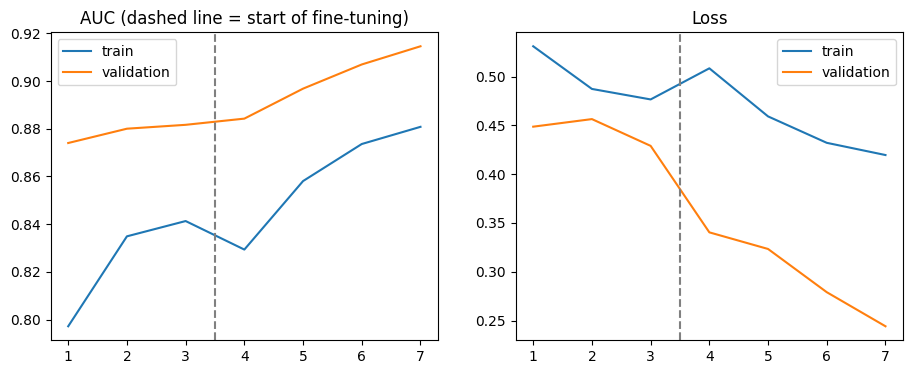

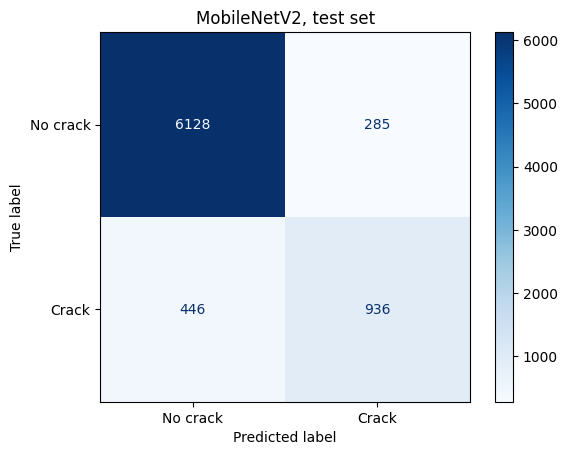

In [21]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

auc  = h1.history["auc"] + h2.history["auc"]
vauc = h1.history["val_auc"] + h2.history["val_auc"]
loss = h1.history["loss"] + h2.history["loss"]
vloss = h1.history["val_loss"] + h2.history["val_loss"]
ep = range(1, len(auc) + 1)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, auc, label="train"); ax[0].plot(ep, vauc, label="validation")
ax[0].axvline(3.5, ls="--", c="gray"); ax[0].set_title("AUC (dashed line = start of fine-tuning)"); ax[0].legend()
ax[1].plot(ep, loss, label="train"); ax[1].plot(ep, vloss, label="validation")
ax[1].axvline(3.5, ls="--", c="gray"); ax[1].set_title("Loss"); ax[1].legend()
plt.savefig("/content/drive/MyDrive/fig_training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["No crack", "Crack"], cmap="Blues")
plt.title("MobileNetV2, test set")
plt.savefig("/content/drive/MyDrive/fig_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

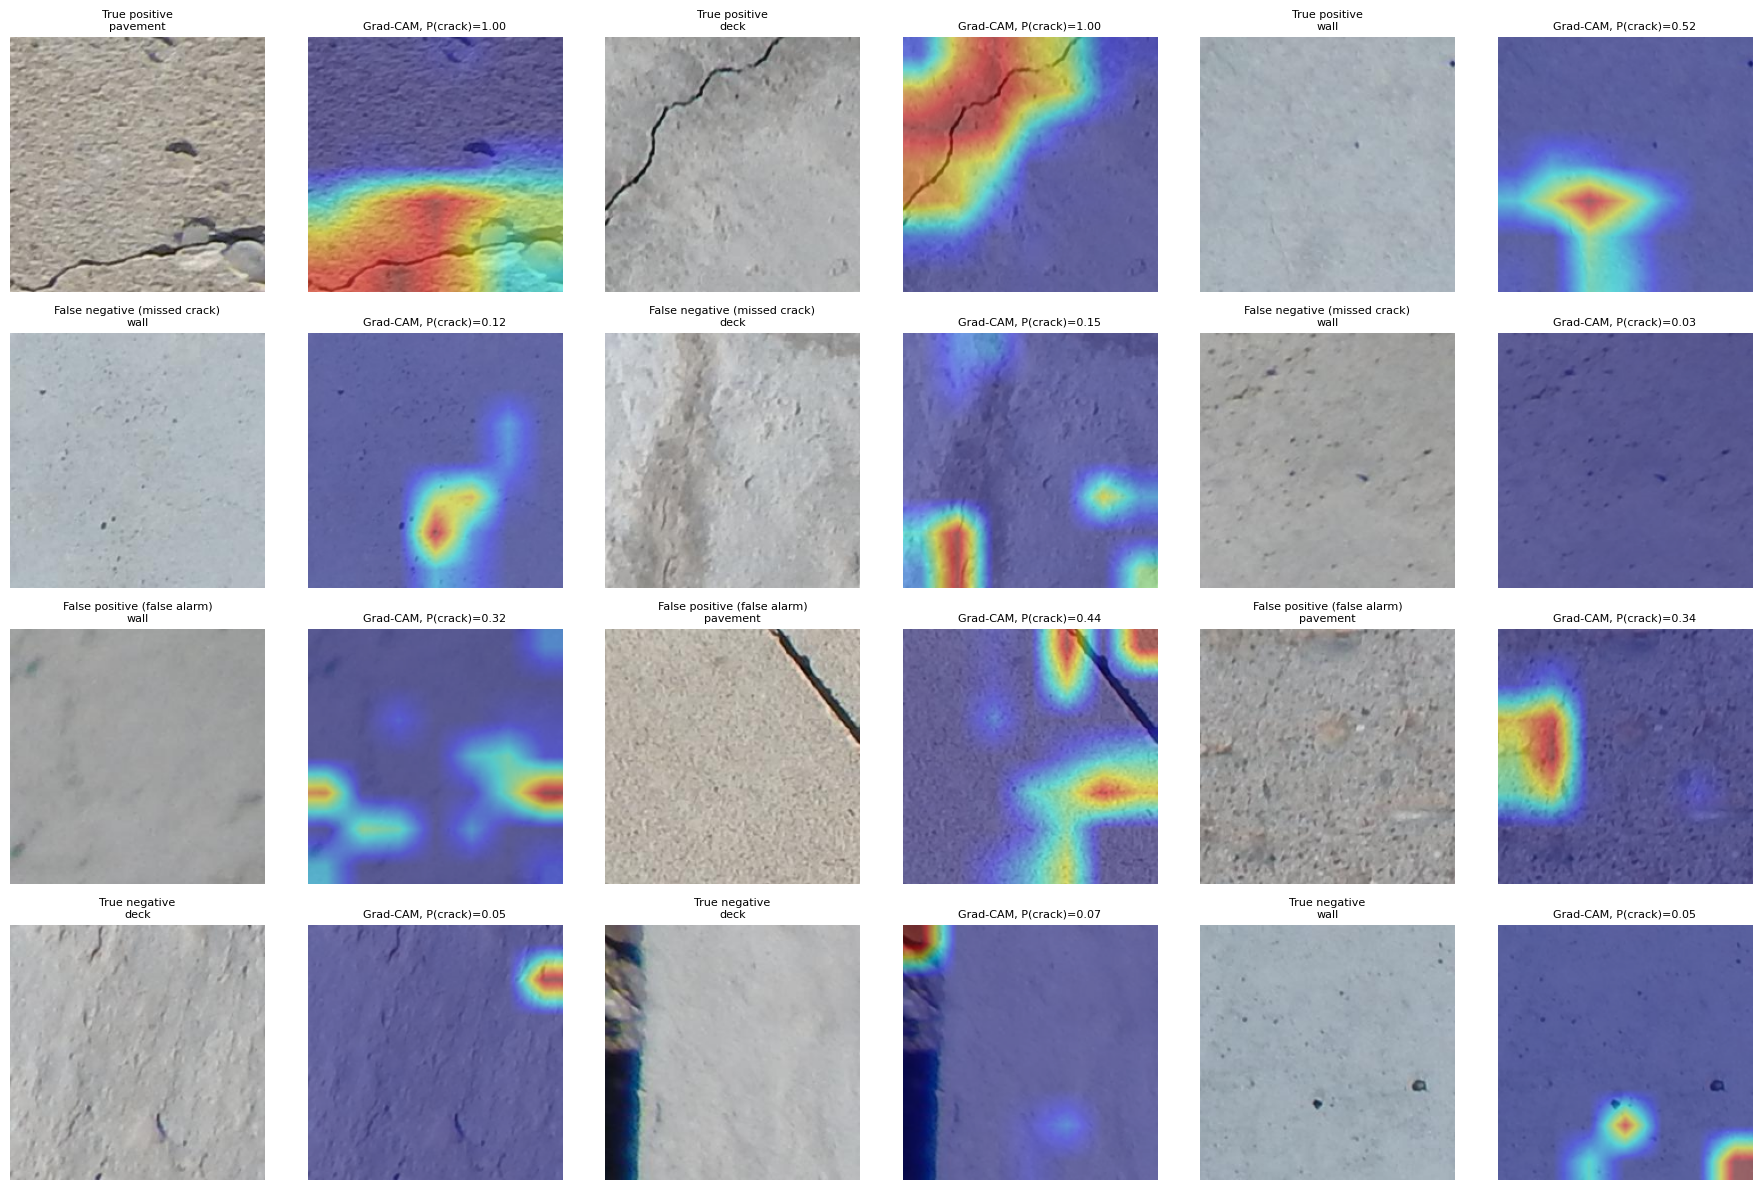

In [22]:
import cv2
from PIL import Image

best_model = tf.keras.models.load_model("/content/drive/MyDrive/mobilenet_best.keras")
base_l = [l for l in best_model.layers if isinstance(l, tf.keras.Model) and "mobilenet" in l.name.lower()][0]
head_dense = best_model.layers[-1]

def gradcam(path):
    img = np.array(Image.open(path).convert("RGB").resize((224, 224))).astype("float32")
    x = tf.keras.applications.mobilenet_v2.preprocess_input(img[None].copy())
    with tf.GradientTape() as tape:
        conv = base_l(x, training=False)
        tape.watch(conv)
        prob = head_dense(tf.reduce_mean(conv, axis=(1, 2)))
    grads = tape.gradient(prob, conv)
    w = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(w * conv, axis=-1))[0].numpy()
    cam = cv2.resize(cam / (cam.max() + 1e-8), (224, 224))
    heat = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)[:, :, ::-1]
    overlay = (0.55 * img + 0.45 * heat).astype("uint8")
    return img.astype("uint8"), overlay, float(prob[0][0])

te_df = df[df.split == "test"].reset_index(drop=True)
te_df["p"], te_df["pred"] = p_test, pred
cats = {
    "True positive":  te_df[(te_df.label == 1) & (te_df.pred == 1)],
    "False negative (missed crack)": te_df[(te_df.label == 1) & (te_df.pred == 0)],
    "False positive (false alarm)":  te_df[(te_df.label == 0) & (te_df.pred == 1)],
    "True negative":  te_df[(te_df.label == 0) & (te_df.pred == 0)],
}

fig, axes = plt.subplots(4, 6, figsize=(18, 12))
for i, (name, d) in enumerate(cats.items()):
    for j, (_, r) in enumerate(d.sample(3, random_state=3).iterrows()):
        orig, ov, pr = gradcam(r.path)
        axes[i, 2*j].imshow(orig);   axes[i, 2*j].axis("off")
        axes[i, 2*j+1].imshow(ov);   axes[i, 2*j+1].axis("off")
        axes[i, 2*j].set_title(f"{name}\n{r.surface}", fontsize=8)
        axes[i, 2*j+1].set_title(f"Grad-CAM, P(crack)={pr:.2f}", fontsize=8)
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/fig_gradcam_examples.png", dpi=130, bbox_inches="tight")
plt.show()

In [23]:
!pip install -q gradio
import gradio as gr

def predict(path):
    if path is None:
        return None, None
    orig, overlay, p = gradcam(path)
    return {"Crack": p, "No crack": 1 - p}, overlay

demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="filepath", label="Upload a close-up concrete photo"),
    outputs=[gr.Label(label="Prediction"), gr.Image(label="Grad-CAM: where the model looked")],
    title="Concrete crack detection (MobileNetV2)",
    description=f"Probability of a crack. Decision threshold used in the report: {t:.2f}. "
                "Informational tool only, not a replacement for a human inspection.",
)
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ff8a99e043cc1ac84e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
